# NYC: Is Affordable Housing Located Near Public Schools?

Spatial analysis with GeoPandas and PySAL (CRP 3850, Cornell University, June 2024; statistical tests added October 2026).

**Research question:** is affordable housing in New York City located in areas with access to public schools?

Data: NYC Open Data (affordable housing production by building, 2020 census tracts, school districts, public school locations). Download links are in the next cell; the data files are not included in this repository.

In [1]:
# Analysis
import geopandas as gpd
import pandas as pd
from numpy.random import seed
import os
import numpy as np

# Graphics
import matplotlib.pyplot as plt
from matplotlib import colors

import seaborn as sns
from pysal.viz import splot
from splot.esda import plot_moran
import contextily as ctx
import rioxarray

sns.set_context(context='paper')

from shapely.geometry import Polygon
from pysal.lib import cg as geometry

import esda
from libpysal import weights

## warnings is a module that allows you to filter warnings
import warnings
## we are going to ignore all warnings (so they won't print)
warnings.filterwarnings("ignore")

In [2]:
# Get data

# Affordable housing production
# source: https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr/about_data
ahp = pd.read_csv('Affordable_Housing_Production.csv')

# NYC Census tracts
# source: https://data.cityofnewyork.us/City-Government/2000-Census-Tracts/ysjj-vb9j (2020 tracts file used)
gdf_CT = gpd.read_file('2020 Census Tracts.zip')
gdf_CT = gdf_CT.to_crs(epsg=4326)

# NYC school districts
# source: https://data.cityofnewyork.us/Education/School-Districts/r8nu-ymqj
gdf_SD = gpd.read_file('School Districts.zip')
gdf_SD = gdf_SD.to_crs(epsg=4326)

# NYC public school locations
# source: https://data.cityofnewyork.us/Education/School-Point-Locations/jfju-ynrr/about_data
gdf_PS = gpd.read_file("Public_School_Locations.zip")
gdf_PS = gdf_PS.to_crs(epsg=4326)

## Clean the data and map each layer

Affordable housing projects are geocoded from their latitude and longitude.

In [3]:
# Clean data
ahp.dropna(subset = ['Longitude', 'Latitude'], inplace = True)
ahp_geometry = gpd.points_from_xy(ahp.Longitude,ahp.Latitude)
gdf_AHP = gpd.GeoDataFrame(ahp,crs="EPSG:4326", geometry= ahp_geometry)
gdf_AHP

,Project ID,Project Name,Project Start Date,Project Completion Date,Building ID,Number,Street,Borough,Postcode,BBL,...,3-BR Units,4-BR Units,5-BR Units,6-BR+ Units,Unknown-BR Units,Counted Rental Units,Counted Homeownership Units,All Counted Units,Total Units,geometry
0,44218,MEC E. 125TH ST. PARCEL B WEST,12/31/2018,02/16/2022,987329.0,2319,3 AVENUE,Manhattan,10035.0,1.017908e+09,...,15,0,0,0,0,297,0,297,404,POINT (-73.93538 40.80426)
1,44223,ROCHESTER SUYDAM PHASE 1,06/30/2021,NaN,927737.0,335,RALPH AVENUE,Brooklyn,11233.0,3.015560e+09,...,0,0,0,0,0,0,13,13,13,POINT (-73.92175 40.67764)
2,44223,ROCHESTER SUYDAM PHASE 1,06/30/2021,NaN,969695.0,35,ROCHESTER AVENUE,Brooklyn,11233.0,3.017090e+09,...,0,0,0,0,0,0,8,8,8,POINT (-73.92747 40.67793)
3,44223,ROCHESTER SUYDAM PHASE 1,06/30/2021,NaN,975702.0,18-22,SUYDAM PLACE,Brooklyn,11233.0,3.017090e+09,...,0,0,0,0,0,0,15,15,15,POINT (-73.92655 40.67782)
4,44223,ROCHESTER SUYDAM PHASE 1,06/30/2021,NaN,977564.0,329,RALPH AVENUE,Brooklyn,11233.0,3.015560e+09,...,0,0,0,0,0,0,10,10,10,POINT (-73.92173 40.67780)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7248,74997,1819 SEDGWICK AVENUE,11/02/2023,NaN,108437.0,1819,SEDGWICK AVENUE,Bronx,10453.0,2.028810e+09,...,1,0,0,0,0,7,0,7,8,POINT (-73.91935 40.85260)
7249,74998,49 BORINQUEN PLACE,10/31/2023,NaN,1011516.0,49,BORINQUEN PLACE,Brooklyn,11211.0,NaN,...,0,0,0,0,0,5,0,5,16,POINT (-73.95670 40.71049)
7250,74999,115 WEST 190 STREET APARTMENTS,10/30/2023,NaN,121294.0,115,WEST 190 STREET,Bronx,10468.0,2.032200e+09,...,0,0,0,0,0,12,0,12,37,POINT (-73.90382 40.86560)
7251,75011,VITAL BK UTICA CRESCENT,12/14/2023,NaN,1011557.0,564,UTICA AVENUE,Brooklyn,11203.0,NaN,...,20,0,0,0,2,322,0,322,322,POINT (-73.93124 40.65966)


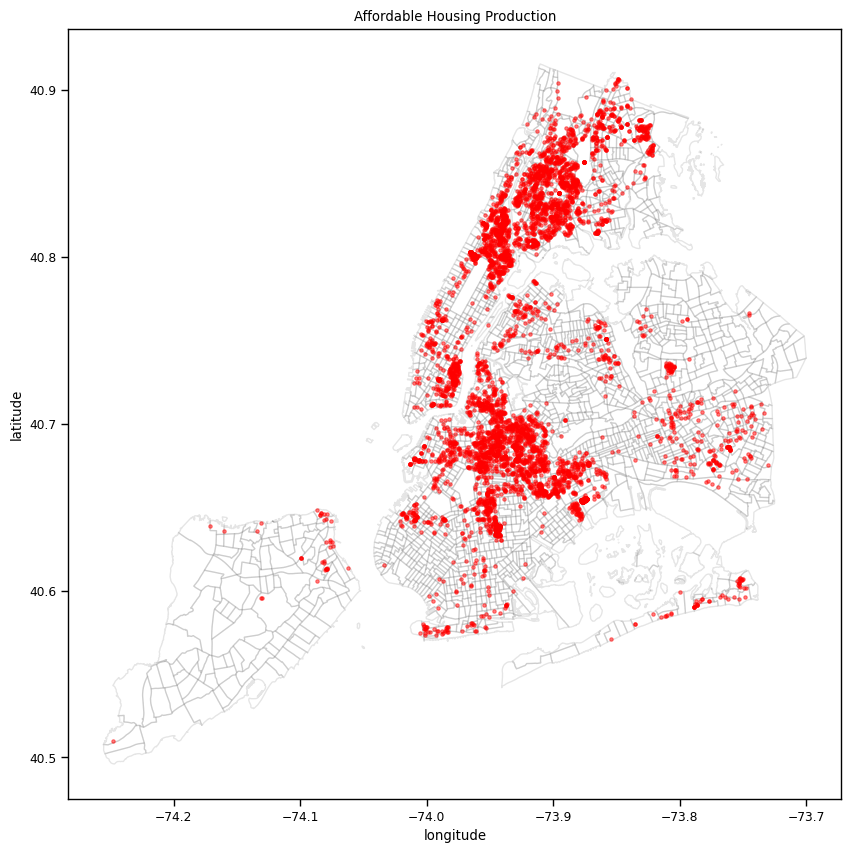

In [4]:
# Plot affordable housing production
fig, ax = plt.subplots(figsize = (10,10))

gdf_CT.plot(color ='none', alpha = 0.1, edgecolor = 'black',linewidth = 1, ax=ax)

gdf_AHP.plot(color='red',  markersize= 6, alpha =0.5, ax=ax)

plt.title('Affordable Housing Production')
plt.xlabel('longitude')
plt.ylabel('latitude')

# save image
fig.savefig('Affordable Housing Production.jpg')

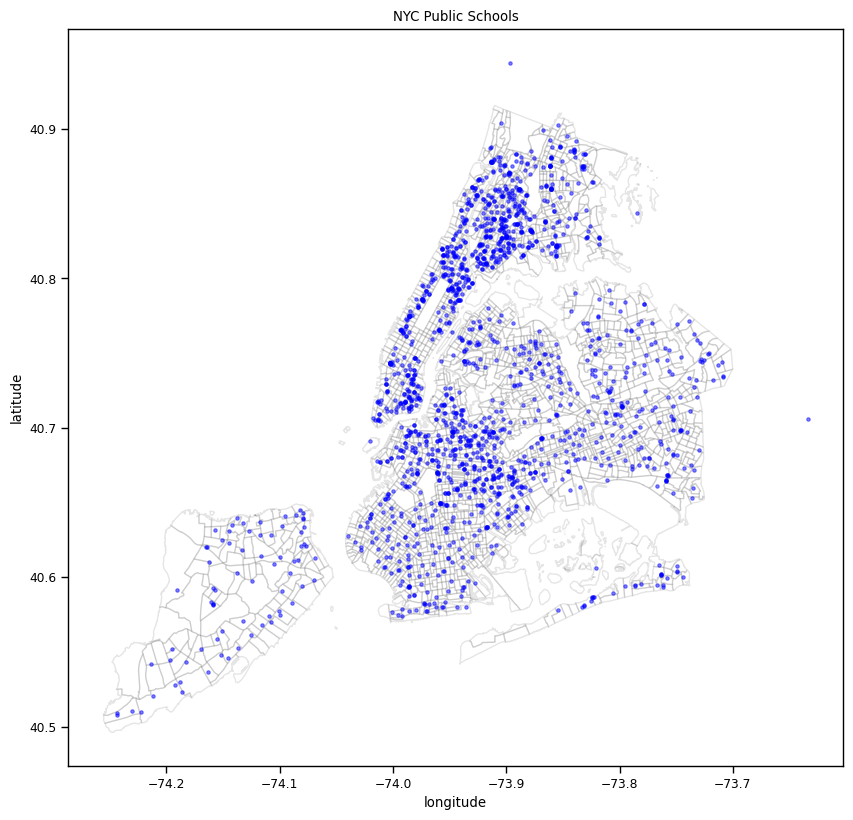

In [5]:
# Plot NYC school locations
fig, ax = plt.subplots(figsize = (10,10))

gdf_CT.plot(color ='none', alpha = 0.1, edgecolor = 'black',linewidth = 1, ax=ax)

gdf_PS.plot(color='blue',  markersize= 6, alpha =0.5, ax=ax)

plt.title('NYC Public Schools')
plt.xlabel('longitude')
plt.ylabel('latitude')
fig.savefig('NYC Public Schools.jpg')

Text(81.66652750830873, 0.5, 'latitude')

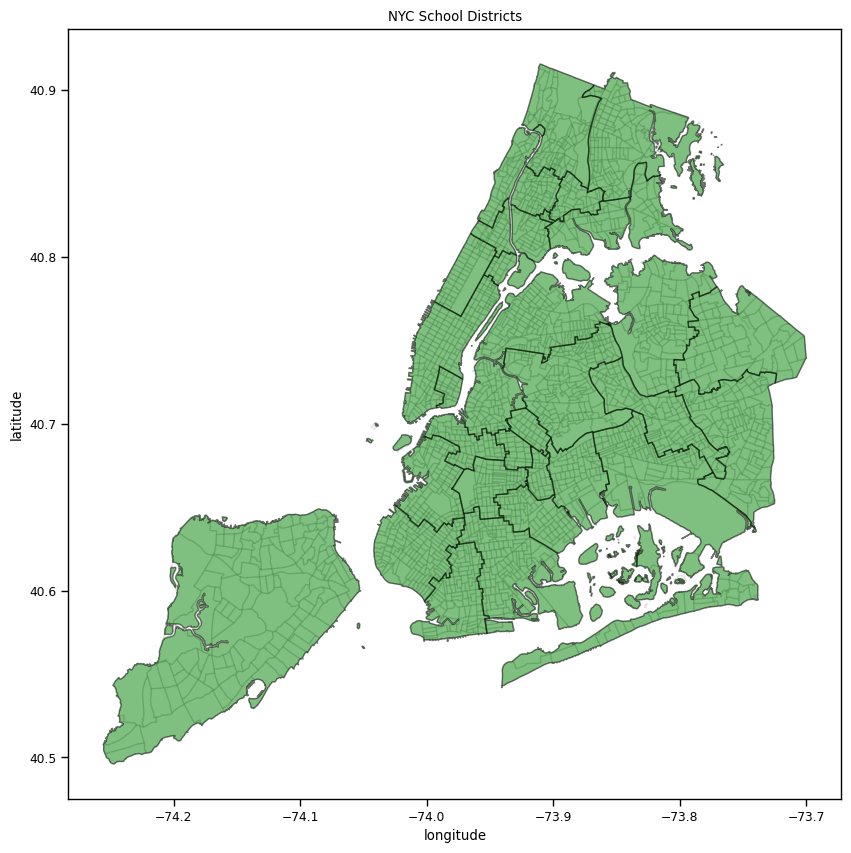

In [6]:
# Plot NYC school districts
fig, ax = plt.subplots(figsize = (10,10))

gdf_CT.plot(color ='none', alpha = 0.1, edgecolor = 'black',linewidth = 1, ax=ax)

gdf_SD.plot(color='green', alpha =0.5, edgecolor = 'black',linewidth = 1, ax=ax)

plt.title('NYC School Districts')
plt.xlabel('longitude')
plt.ylabel('latitude')



Text(80.79166666666667, 0.5, 'latitude')

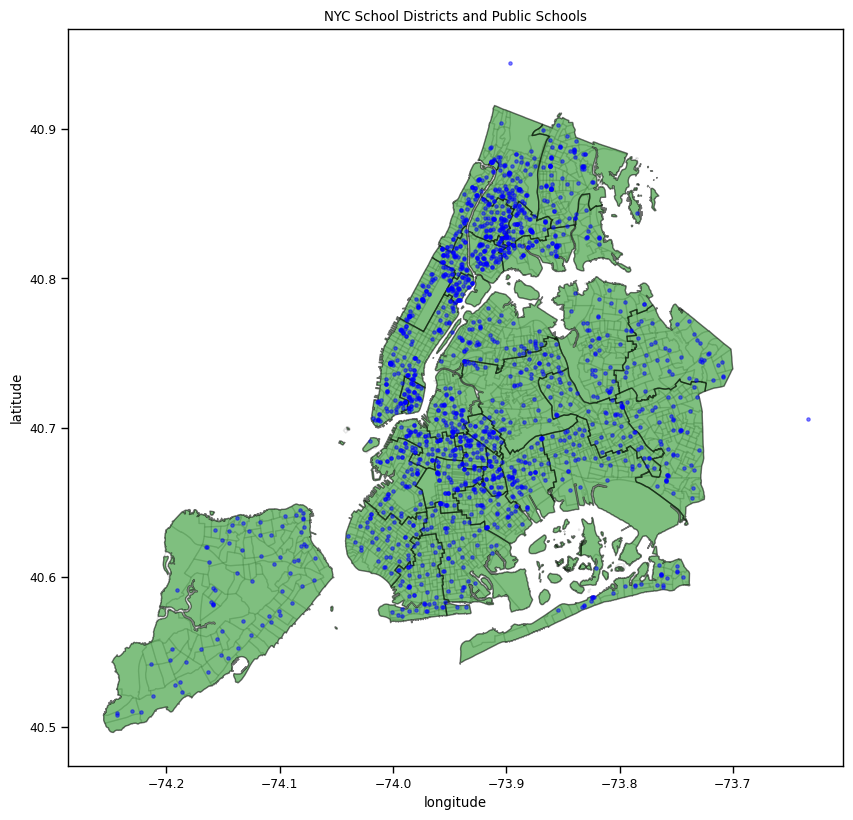

In [7]:
# Plot NYC school districts and public schools
fig, ax = plt.subplots(figsize = (10,10))

gdf_CT.plot(color ='none', alpha = 0.1, edgecolor = 'black',linewidth = 1, ax=ax)

gdf_SD.plot(color='green', alpha =0.5, edgecolor = 'black',linewidth = 1, ax=ax)

gdf_PS.plot(color='blue',  markersize= 6, alpha =0.5, ax=ax)

plt.title('NYC School Districts and Public Schools')
plt.xlabel('longitude')
plt.ylabel('latitude')

# save image
#fig.savefig('NYC SDs and PS.jpg')

## Count public schools per school district

In [8]:
gdf_SD['school_dis'] = gdf_SD['school_dis'].astype(int)

In [9]:
gdf_SD

,school_dis,shape_area,shape_leng,geometry
0,18,1.751917e+08,120925.187236,"MULTIPOLYGON (((-73.86327 40.58388, -73.86381 ..."
1,31,1.604157e+09,430016.498898,"MULTIPOLYGON (((-74.05051 40.56642, -74.05047 ..."
2,20,2.427385e+08,94300.786485,"POLYGON ((-74.02553 40.65148, -74.02491 40.651..."
3,3,1.134127e+08,51922.328523,"POLYGON ((-73.95672 40.78660, -73.95716 40.785..."
4,9,8.298072e+07,44396.442733,"MULTIPOLYGON (((-73.93309 40.82823, -73.93307 ..."
5,22,3.856116e+08,270190.685308,"MULTIPOLYGON (((-73.91990 40.59960, -73.91996 ..."
6,6,9.634605e+07,68850.712689,"POLYGON ((-73.92641 40.87762, -73.92635 40.877..."
7,13,1.048711e+08,86649.096374,"POLYGON ((-73.97906 40.70595, -73.97924 40.705..."
8,16,4.676380e+07,35848.908106,"POLYGON ((-73.93312 40.69579, -73.93237 40.695..."
9,32,5.189832e+07,37251.060688,"POLYGON ((-73.91181 40.70343, -73.91290 40.702..."


In [10]:
gdf_PS

,ATS_CODE,BORO,BORONUM,LOC_CODE,SCHOOLNAME,SCH_TYPE,MANAGED_BY,GEO_DISTRI,ADMIN_DIST,ADDRESS,STATE_CODE,ZIP,PRINCIPAL,PRIN_PH,FAX,GRADES,City,geometry
0,15K001,K,2.0,K001,P.S. 001 THE BERGEN,Elementary,1,15,15,309 47 STREET,NY,11220,Jennifer Eusanio,718-567-7661,718-567-9771,"PK,0K,01,02,03,04,05,SE",BROOKLYN,POINT (-74.01177 40.64915)
1,17K002,K,2.0,K002,M.S. 002,Junior High-Intermediate-Middle,1,17,17,655 PARKSIDE AVENUE,NY,11226,ADRIENNE SPENCER,718-462-6992,718-284-7717,"06,07,08,SE",BROOKLYN,POINT (-73.95122 40.65642)
2,21K095,K,2.0,K095,P.S. 095 THE GRAVESEND,K-8,1,21,21,345 VAN SICKLEN STREET,NY,11223,Janet Ndzibah,718-449-5050,718-449-3047,"PK,0K,01,02,03,04,05,06,07,08,SE",BROOKLYN,POINT (-73.97488 40.59574)
3,21K096,K,2.0,K096,I.S. 096 SETH LOW,Junior High-Intermediate-Middle,1,21,21,99 AVENUE P,NY,11204,Denise Sandra Levinsky,718-236-1344,718-236-2397,"06,07,08,SE",BROOKLYN,POINT (-73.98491 40.60779)
4,21K097,K,2.0,K097,P.S. 97 THE HIGHLAWN,Elementary,1,21,21,1855 STILLWELL AVENUE,NY,11223,KRISTINE MUSTILLO,718-372-7393,718-372-3842,"PK,0K,01,02,03,04,05,SE",BROOKLYN,POINT (-73.98576 40.60125)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1704,84Q359,Q,4.0,Q359,Academy of the City Charter School,Elementary,2,30,84,36-14 12TH STREET,NY,11106,NaN,NaN,NaN,"0K,01,SE",QUEENS,POINT (-73.93963 40.76033)
1705,84X538,X,2.0,X538,Icahn Charter School 5,Elementary,2,11,84,1500 PELHAM PARKWAY SOUTH,NY,10461,NaN,NaN,NaN,"0K,01,02,SE",BRONX,POINT (-73.84301 40.85679)
1706,84X539,X,2.0,X539,The New Visions Charter High School for Advanc...,High school,2,10,84,99 TERRACE VIEW AVENUE,NY,10463,NaN,NaN,NaN,"09,SE",BRONX,POINT (-73.91340 40.87791)
1707,84X553,X,2.0,X553,The New Visions Charter High School for the Hu...,High school,2,10,84,99 TERRACE VIEW AVENUE,NY,10463,NaN,NaN,NaN,"09,SE",BRONX,POINT (-73.91325 40.87783)


In [11]:
# Merge school location and district datasets for spatial weight analysis
gdf_ed = gdf_PS.groupby('GEO_DISTRI')[['geometry']].count().reset_index()
gdf_ed

,GEO_DISTRI,geometry
0,0,2
1,1,36
2,2,119
3,3,55
4,4,43
5,5,45
6,6,48
7,7,54
8,8,64
9,9,73


In [12]:
gdf_ed =gdf_ed.rename(columns ={'geometry': 'school_count'}) 

In [13]:
final = gdf_SD.merge(gdf_ed, left_on = 'school_dis', right_on = 'GEO_DISTRI')

In [14]:
final.head()

,school_dis,shape_area,shape_leng,geometry,GEO_DISTRI,school_count
0,18,1.751917e+08,120925.187236,"MULTIPOLYGON (((-73.86327 40.58388, -73.86381 ...",18,40
1,31,1.604157e+09,430016.498898,"MULTIPOLYGON (((-74.05051 40.56642, -74.05047 ...",31,73
2,20,2.427385e+08,94300.786485,"POLYGON ((-74.02553 40.65148, -74.02491 40.651...",20,44
3,3,1.134127e+08,51922.328523,"POLYGON ((-73.95672 40.78660, -73.95716 40.785...",3,55
4,9,8.298072e+07,44396.442733,"MULTIPOLYGON (((-73.93309 40.82823, -73.93307 ...",9,73


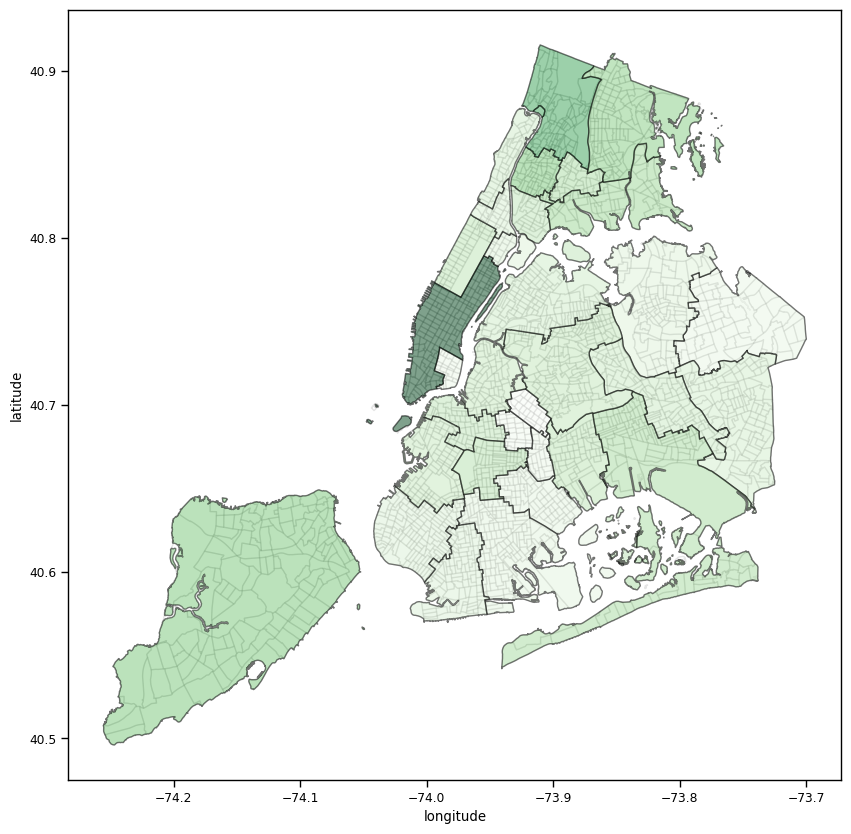

In [15]:
# Plot NYC school districts by number of schools
fig, ax = plt.subplots(figsize = (10,10))

gdf_CT.plot(color ='none', alpha = 0.1, edgecolor = 'black',linewidth = 1, ax=ax)

final.plot(column='school_count', cmap='Greens', alpha =0.5, edgecolor = 'black',linewidth = 1, ax=ax)

plt.xlabel('longitude')
plt.ylabel('latitude')

# save image
fig.savefig('NYCSDbyschools.jpg')

## Local spatial clustering (LISA)

k-nearest-neighbor weights (k = 4), then local Moran's I for affordable rental units (by building) and school counts (by district). Hot spots are significant at p < 0.05.

In [16]:
# Create weights
w4 = weights.KNN.from_dataframe(gdf_AHP, k=4)

In [17]:
w4.transform = 'R'

In [18]:
ws = weights.KNN.from_dataframe(final, k=4)

In [19]:
lisa_housing = esda.moran.Moran_Local(gdf_AHP['Counted Rental Units'], w4)
lisa_schools = esda.moran.Moran_Local(final['school_count'], ws)

In [20]:
from splot import esda as esdaplot

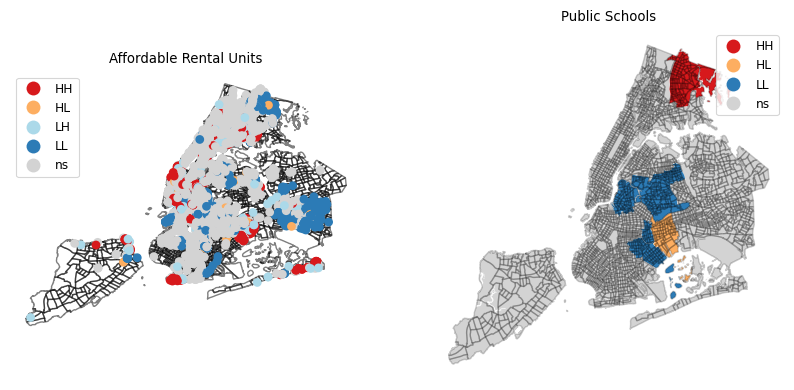

In [21]:
f, ax = plt.subplots(1,2,figsize=(10,10))

gdf_CT.plot(color ='none', alpha = 0.5, edgecolor = 'black',linewidth = 1, ax=ax[0])
esdaplot.lisa_cluster(lisa_housing, gdf_AHP, p=0.05, ax=ax[0])

esdaplot.lisa_cluster(lisa_schools, final, p=0.05, ax=ax[1])
gdf_CT.plot(color ='none', alpha = 0.2, edgecolor = 'black',linewidth = 1, ax=ax[1])

ax[0].set_title("Affordable Rental Units")
ax[1].set_title("Public Schools")

f.savefig('lisas.jpg')

Comparing these two maps by eye, the original poster concluded the clusters did not overlap, so affordable housing "seems to not be related" to school locations. The cells below test that directly.

## Global Moran's I: is each layer clustered overall?

In [22]:
# Global Moran's I: is each layer clustered overall?
from numpy.random import seed
seed(12345)  # permutation tests are random; this makes p-values repeatable

moran_housing = esda.Moran(gdf_AHP['Counted Rental Units'], w4)
moran_schools = esda.Moran(final['school_count'], ws)

print(f"Affordable rental units: Moran's I = {moran_housing.I:.3f}, p = {moran_housing.p_sim:.3f}")
print(f"Public schools per district: Moran's I = {moran_schools.I:.3f}, p = {moran_schools.p_sim:.3f}")

Affordable rental units: Moran's I = 0.351, p = 0.001
Public schools per district: Moran's I = 0.203, p = 0.019


**Result:** both layers are significantly clustered (affordable rental units: I = 0.351, p = 0.001; schools: I = 0.203, p = 0.019).

## Direct test: do districts with more schools have more affordable rental units?

Affordable rental units are totaled within each school district with a spatial join, then compared with school counts.

Districts compared: 33
Pearson r = 0.653 (p = 0.000); Spearman rho = 0.601 (p = 0.000)


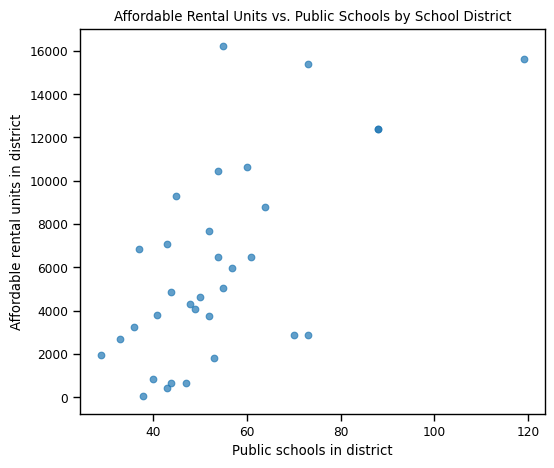

In [23]:
# Total affordable rental units in each school district, then compare with school counts
from scipy import stats

ahp_in_districts = gpd.sjoin(gdf_AHP, gdf_SD[['school_dis', 'geometry']],
                             how='inner', predicate='within')
units_by_district = (ahp_in_districts.groupby('school_dis')['Counted Rental Units']
                     .sum().reset_index(name='rental_units'))

district_compare = (final[['school_dis', 'school_count']]
                    .merge(units_by_district, on='school_dis', how='left')
                    .fillna({'rental_units': 0}))

r, p = stats.pearsonr(district_compare['school_count'], district_compare['rental_units'])
rho, p_s = stats.spearmanr(district_compare['school_count'], district_compare['rental_units'])
print(f"Districts compared: {len(district_compare)}")
print(f"Pearson r = {r:.3f} (p = {p:.3f}); Spearman rho = {rho:.3f} (p = {p_s:.3f})")

# Scatter plot for the README
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(district_compare['school_count'], district_compare['rental_units'], alpha=0.7)
ax.set_xlabel('Public schools in district')
ax.set_ylabel('Affordable rental units in district')
ax.set_title('Affordable Rental Units vs. Public Schools by School District')
fig.savefig('units_vs_schools.jpg', bbox_inches='tight')

**Result:** a positive relationship (Spearman ρ = 0.601, p < 0.001). Note: this run has 33 rows because one school district is stored as two shapes; the next cell merges them into 32 districts.

## Controlling for district size

Larger districts can hold more of everything. First, densities per km²:

In [24]:
# Control for district size: compare densities instead of raw counts
areas = (final.groupby('school_dis')
         .agg(school_count=('school_count', 'first'), shape_area=('shape_area', 'sum'))
         .reset_index())
dens = (areas.merge(units_by_district, on='school_dis', how='left')
        .fillna({'rental_units': 0}))
dens['area_km2'] = dens['shape_area'] * 0.09290304 / 1e6   # shape_area is in square feet
dens['schools_per_km2'] = dens['school_count'] / dens['area_km2']
dens['units_per_km2'] = dens['rental_units'] / dens['area_km2']

print(f"Unique districts: {len(dens)} (rows in final: {len(final)})")
rho_d, p_d = stats.spearmanr(dens['schools_per_km2'], dens['units_per_km2'])
print(f"Density: Spearman rho = {rho_d:.3f} (p = {p_d:.3f})")

Unique districts: 32 (rows in final: 33)
Density: Spearman rho = 0.923 (p = 0.000)


ρ = 0.923 is inflated: dividing both measures by the same area creates correlation on its own (a known trap with shared denominators), especially since district sizes vary roughly tenfold. A partial correlation, holding area constant instead, is the cleaner control:

In [25]:
# Partial correlation: schools vs. affordable units, holding district area constant
# (ranks, so a few very large projects don't dominate)
from scipy.stats import rankdata

def residuals(y, x):
    slope, intercept = np.polyfit(x, y, 1)
    return y - (slope * x + intercept)

r_units = rankdata(dens['rental_units'])
r_schools = rankdata(dens['school_count'])
r_area = rankdata(dens['area_km2'])

partial_r, partial_p = stats.pearsonr(residuals(r_schools, r_area), residuals(r_units, r_area))
print(f"Partial Spearman, controlling for district area: {partial_r:.3f} (p = {partial_p:.3f})")

Partial Spearman, controlling for district area: 0.770 (p = 0.000)


**Result:** the relationship holds with district area held constant (partial Spearman ρ = 0.770, p < 0.001, 32 districts).

## Conclusion

Affordable rental units and public schools co-locate at the school-district level, reversing the poster's visual conclusion. Both likely follow population density, so this shows co-location, not that affordable housing is deliberately built near schools. Next steps: control for population, and measure access directly (e.g., distance from each building to its nearest school).